# Lorenz–96 frequency spectra and AC bandwidths

Example: `trajectory_a_000.npz` from the dense Config A benchmark.
Run the cells in order using the `panda_pilot` environment (NumPy, Matplotlib,
SciPy, and scikit-learn). The notebook works from the repository root or `notebooks/`.

Each row pairs the raw FFT magnitude $|Z_{c,k}|$ with one-sided energy
$E_{c,k}=w_k|Z_{c,k}|^2$ for the same channel. Vertical lines mark the lowest
frequency retaining 90%, 99%, or 99.9% of that channel's **AC energy**.
DC is preserved in the computed spectra but excluded from bandwidth estimation
and plotting. No mean subtraction, smoothing, or window is applied.

Energy is unnormalized, not a power spectral density. Both axes are logarithmic;
zero-valued bins are omitted. By default, every positive-frequency bin is shown,
from approximately 0.005 to 500 cycles per simulation-time unit. DC is omitted
because zero cannot be displayed on a logarithmic frequency axis.
Pass `max_frequency=...` to inspect a smaller range. Cutoffs always use the complete
spectrum. Channel indices are zero-based.


In [7]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/data/sampling_interval").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Run this notebook inside the MultiscaleDynamicsAI repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.lorenz96.simulate import Trajectory
from src.data.sampling_interval import (
    compute_fft,
    compute_spectral_energy,
    estimate_channel_bandwidths,
)

DATA_DIR = ROOT / "outputs/lorenz96_benchmark/dense_trajectories_a"
FILENAME = "trajectory_a_000.npz"
metadata = json.loads((DATA_DIR / "metadata.json").read_text())
entry = next(record for record in metadata if record["filename"] == FILENAME)
K = entry["parameters"]["K"]
J = entry["parameters"]["J"]
assert (K, J) == (6, 4), "This example expects six slow variables and four fast variables per group."

with np.load(DATA_DIR / FILENAME) as data:
    trajectory = Trajectory(time=data["time"].copy(), state=data["state"].copy())
assert trajectory.state.shape == (K * (1 + J), trajectory.time.size)

frequency_spectrum = compute_fft(trajectory)
energy_spectrum = compute_spectral_energy(frequency_spectrum)
CUTOFFS = (0.9, 0.99, 0.999)
bandwidths = {
    cutoff: estimate_channel_bandwidths(
        energy_spectrum, cumulative_energy_cutoff=cutoff
    )
    for cutoff in CUTOFFS
}
print(f"{FILENAME}: {trajectory.state.shape[0]} channels, {trajectory.time.size:,} observations")
print(f"Time interval: [{trajectory.time[0]:g}, {trajectory.time[-1]:g}]")
print(f"Sample spacing: {frequency_spectrum.sampling_interval:g}; frequency units: cycles / simulation time")

trajectory_a_000.npz: 30 channels, 200,001 observations
Time interval: [50, 250]
Sample spacing: 0.001; frequency units: cycles / simulation time


In [8]:
def plot_channel_spectra(channel_indices, channel_labels, title, *, max_frequency=None):
    """Pair FFT magnitude and energy panels, with identical bandwidth annotations."""
    channel_indices = list(channel_indices)
    frequencies = frequency_spectrum.frequency
    if max_frequency is None:
        max_frequency = frequencies[-1]
    visible = (frequencies > 0) & (frequencies <= max_frequency)
    colors = ("#d97706", "#059669", "#7c3aed")
    styles = ("--", "-.", ":")
    fig, axes = plt.subplots(
        len(channel_indices), 2,
        figsize=(16, 3.3 * len(channel_indices)),
        sharex=True, squeeze=False, constrained_layout=True,
    )
    fig.suptitle(title, fontsize=16)

    for row, (channel, label) in enumerate(zip(channel_indices, channel_labels)):
        magnitude = np.abs(frequency_spectrum.coefficients[channel])
        energy = energy_spectrum.energy[channel]
        for column, (values, ylabel, panel_title) in enumerate((
            (magnitude, r"$|Z_k|$", "FFT magnitude"),
            (energy, r"$E_k$ (unnormalized)", "One-sided energy"),
        )):
            ax = axes[row, column]
            positive_values = np.where(values[visible] > 0, values[visible], np.nan)
            ax.loglog(frequencies[visible], positive_values, color="#2563eb", linewidth=0.8)
            for cutoff, color, style in zip(CUTOFFS, colors, styles):
                frequency = bandwidths[cutoff][channel]
                ax.axvline(
                    frequency, color=color, linestyle=style, linewidth=1.4,
                    label=f"{100 * cutoff:g}% AC: f = {frequency:.6g}",
                )
            ax.set_title(f"{label} — {panel_title}", fontsize=11)
            ax.set_ylabel(ylabel)
            ax.set_xlim(frequencies[1], max_frequency)
            ax.grid(True, which="major", alpha=0.2)
            ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    for ax in axes[-1]:
        ax.set_xlabel("Frequency (cycles / simulation time; log scale)")
    plt.show()

## Six slow variables — 12 panels

Rows are $X_0,\ldots,X_5$; left column is FFT magnitude and right column is energy.
Each panel lists the three cutoff frequencies in its legend. Coincident lines mean
multiple retained-energy requirements select the same frequency bin.

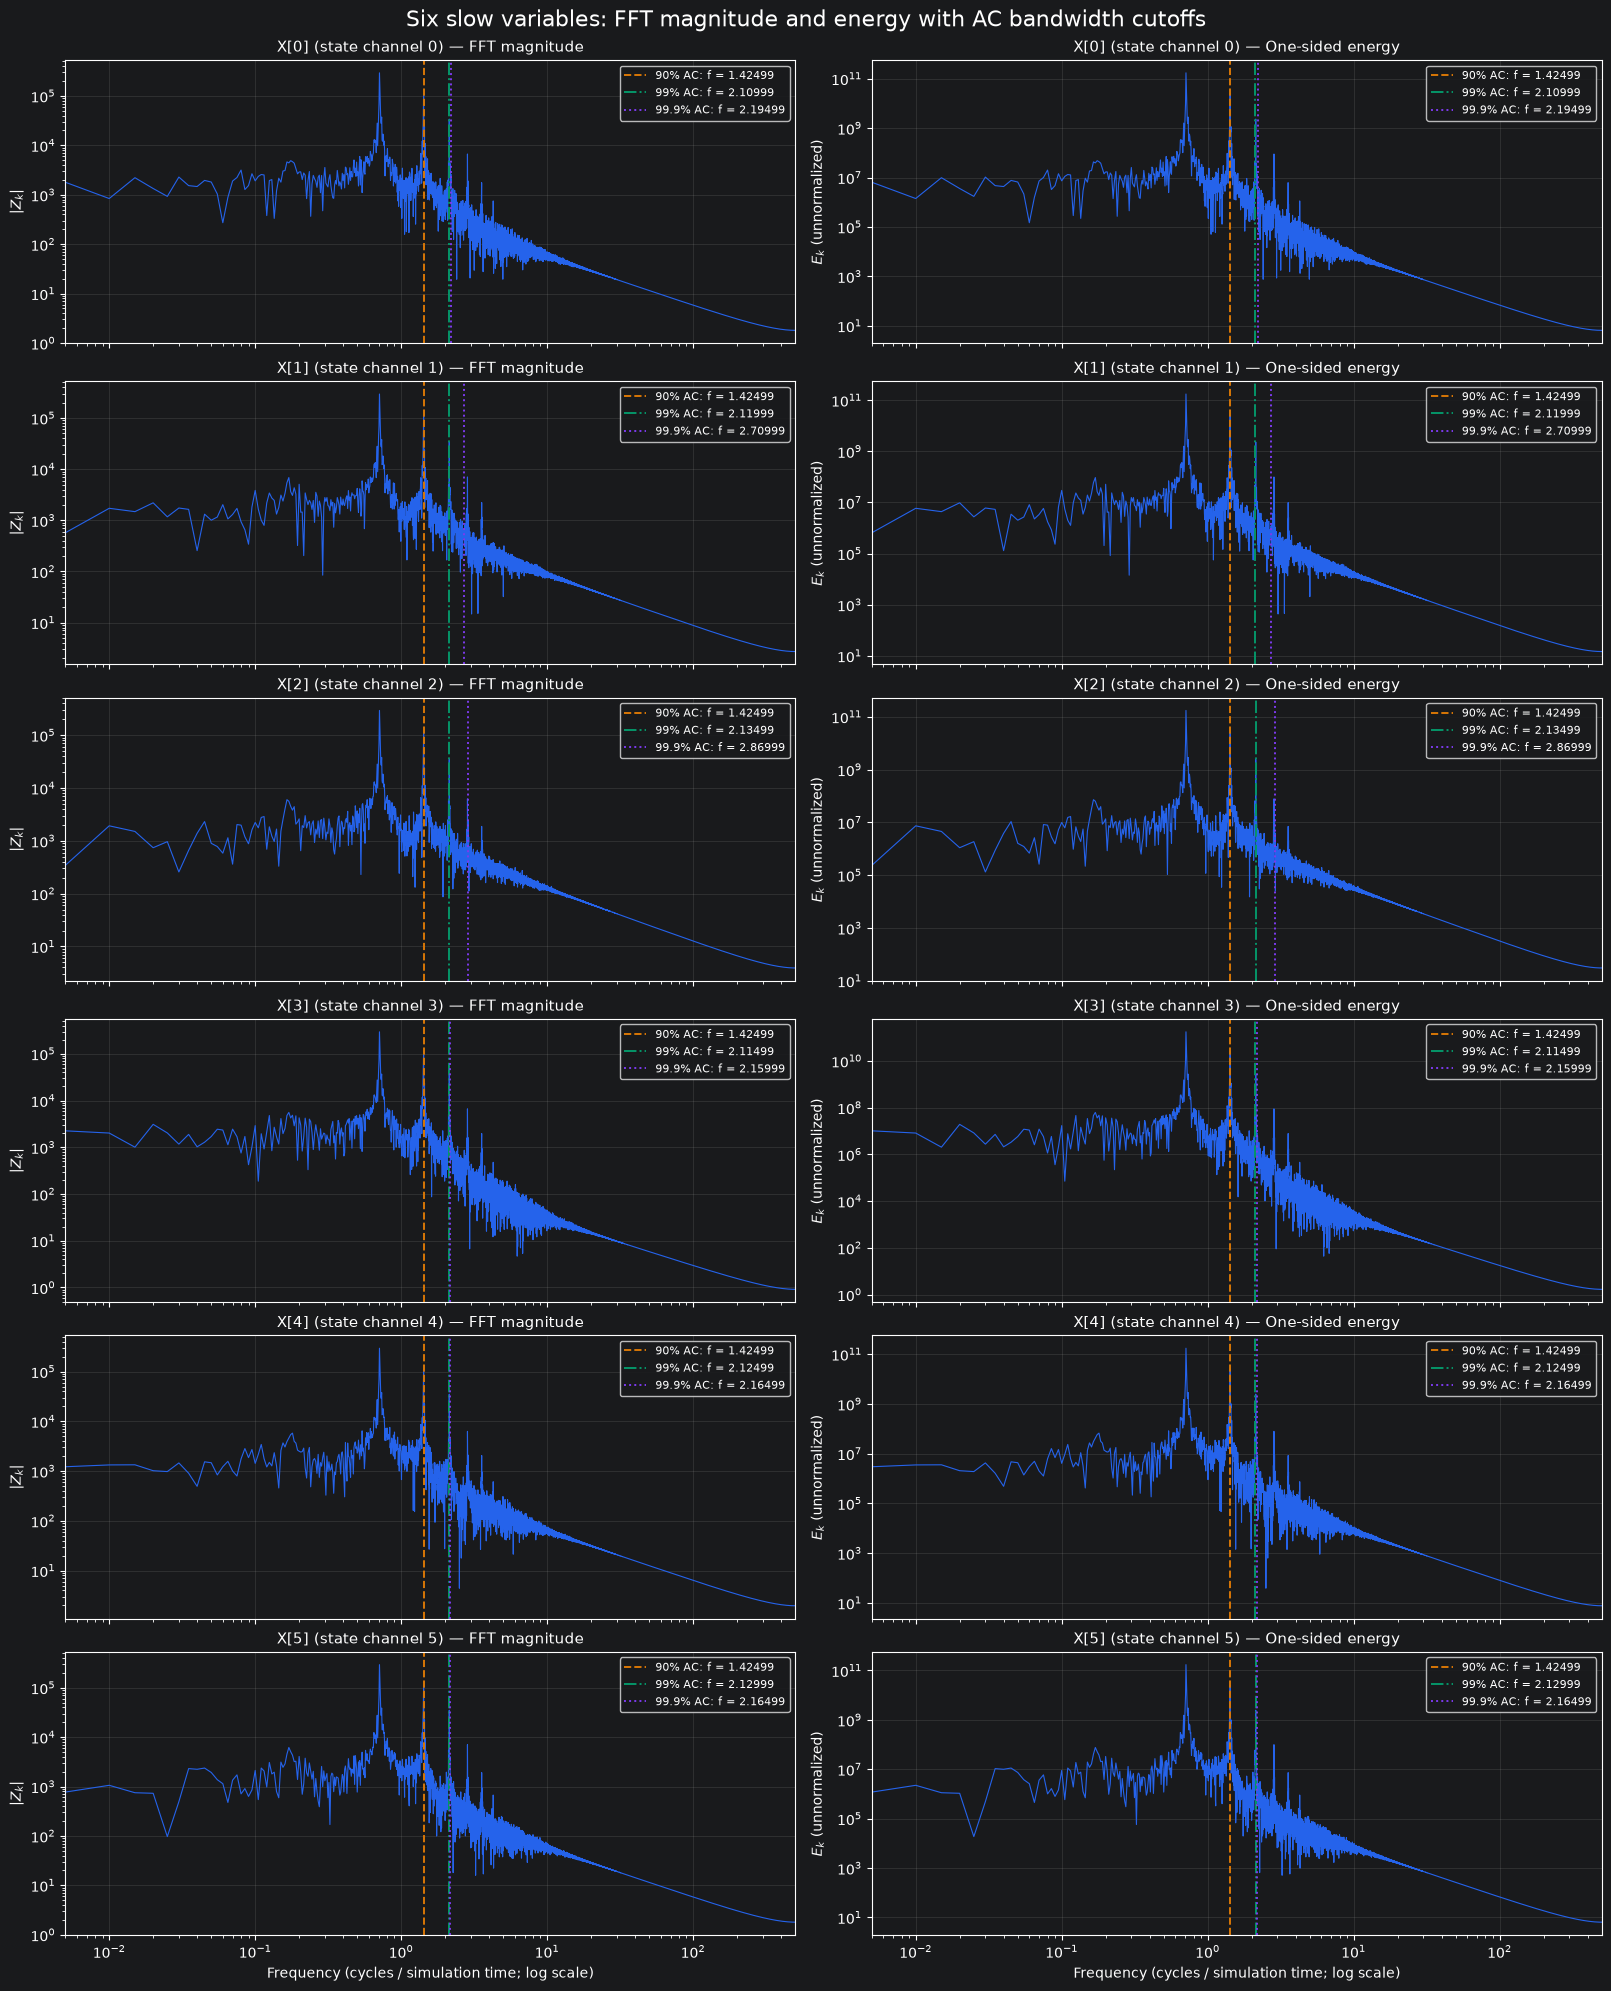

In [9]:
plot_channel_spectra(
    range(K),
    [f"X[{k}] (state channel {k})" for k in range(K)],
    "Six slow variables: FFT magnitude and energy with AC bandwidth cutoffs",
)

## First fast group — 8 panels

Rows are $Y_{0,0},\ldots,Y_{0,3}$, the four fast variables associated with $X_0$.
The saved state layout places fast variable $(k,j)$ at channel $K+kJ+j$;
therefore this group occupies state channels 6 through 9.

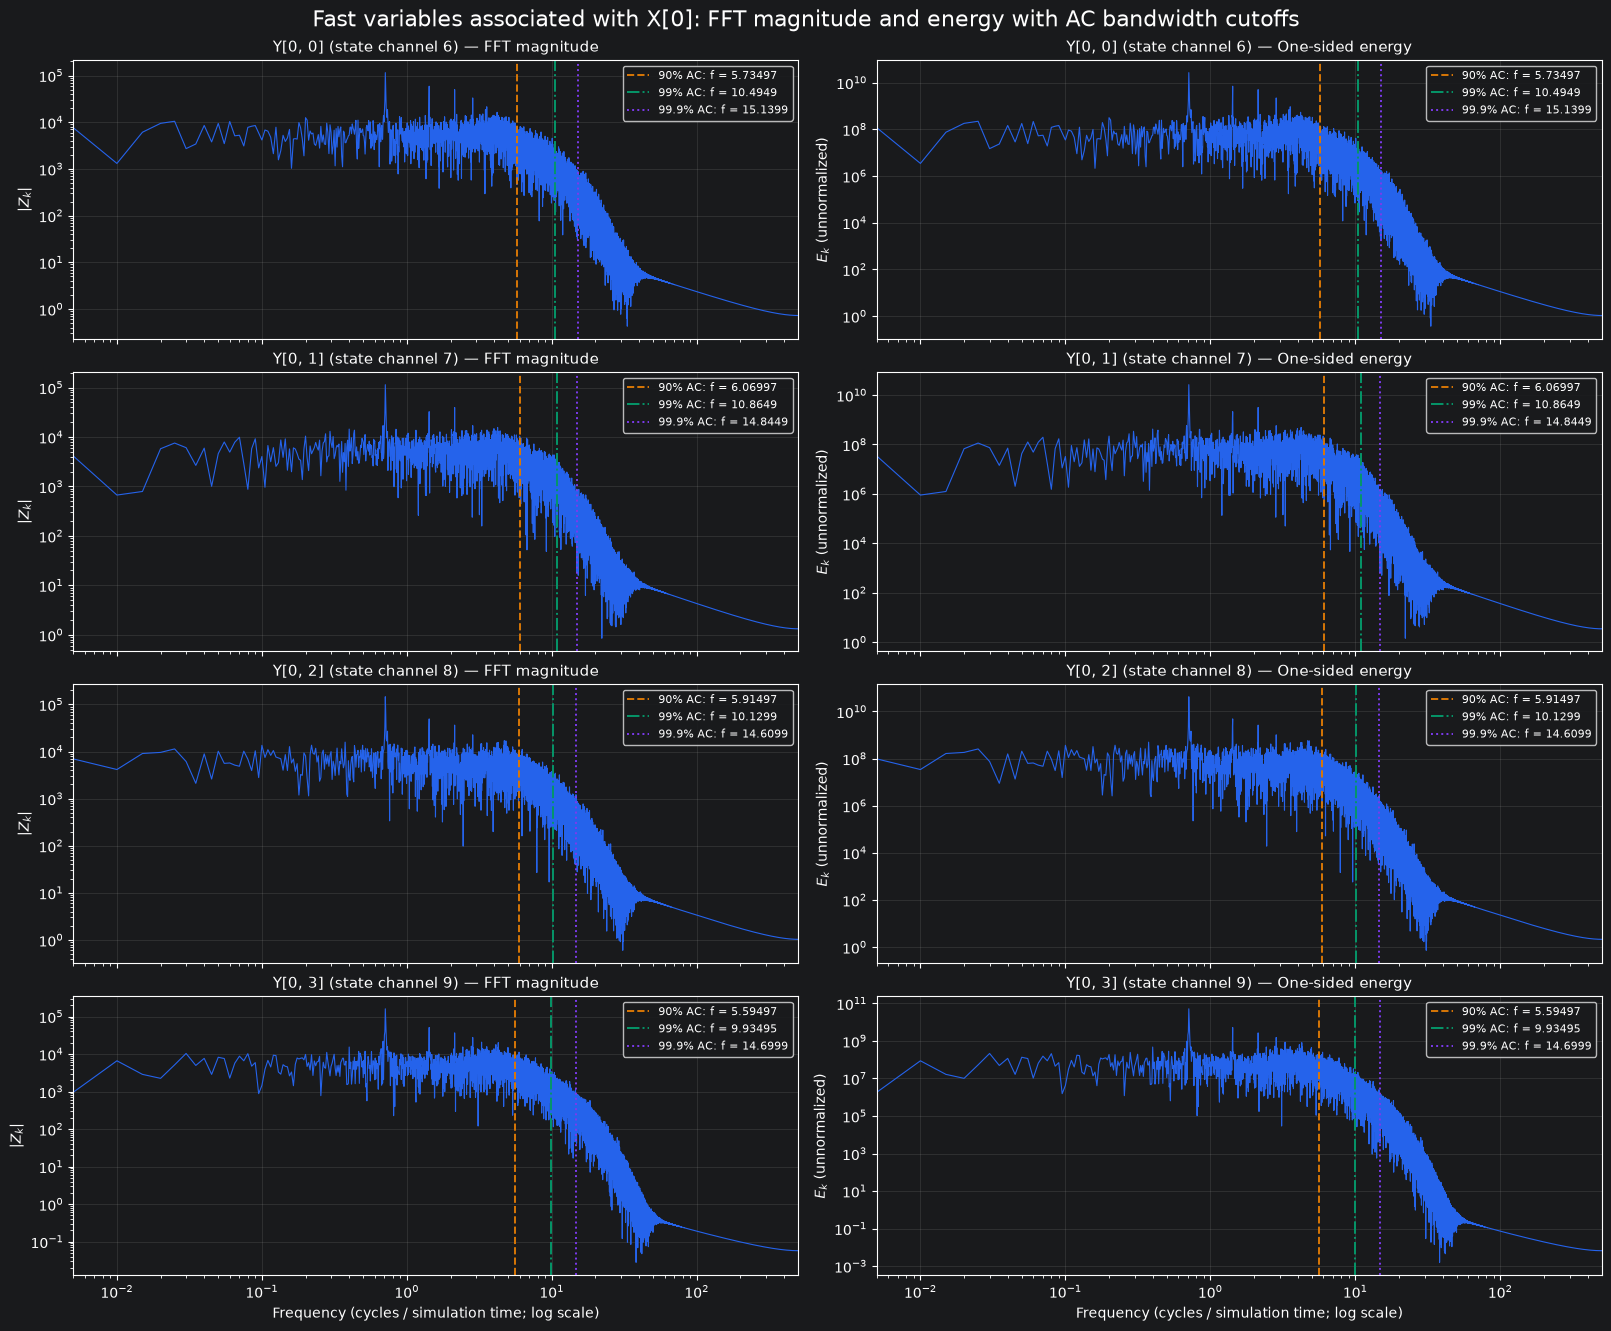

In [10]:
plot_channel_spectra(
    range(K, K + J),
    [f"Y[0, {j}] (state channel {K + j})" for j in range(J)],
    "Fast variables associated with X[0]: FFT magnitude and energy with AC bandwidth cutoffs",
)

## Smallest-ε example: time-domain signals for trajectory 015

This section loads `trajectory_a_015.npz` ($\epsilon=1/512$) separately, leaving
all trajectory-000 spectrum variables unchanged. It shows $X_0$ and its four
associated fast variables $Y_{0,0},\ldots,Y_{0,3}$, one per panel.
Both axes are linear. The first figure covers the full saved record; the second
zooms into a short interval to show individual samples of the fast signals.
The saved spacing is 0.001; connecting lines interpolate visually between samples
and do not reveal any unresolved behavior between observations.

In [11]:
TIME_FILENAME = "trajectory_a_015.npz"
time_entry = next(record for record in metadata if record["filename"] == TIME_FILENAME)
time_K = time_entry["parameters"]["K"]
time_J = time_entry["parameters"]["J"]
slow_index = 0
with np.load(DATA_DIR / TIME_FILENAME) as data:
    time_trajectory = Trajectory(time=data["time"].copy(), state=data["state"].copy())

time_channel_indices = [slow_index] + [
    time_K + slow_index * time_J + j for j in range(time_J)
]
time_channel_labels = [f"X[{slow_index}]"] + [
    f"Y[{slow_index}, {j}]" for j in range(time_J)
]
print(f"{TIME_FILENAME}: eps = {time_entry['parameters']['eps']:g}")
print(f"State channels: {time_channel_indices}; saved spacing: {np.diff(time_trajectory.time).mean():g}")


def plot_time_signals(start=None, duration=None, *, show_samples=False):
    """Plot the selected slow variable and its fast group in separate panels."""
    times = time_trajectory.time
    start = times[0] if start is None else start
    end = times[-1] if duration is None else start + duration
    if end <= start:
        raise ValueError("The displayed time interval must have positive duration.")
    visible = (times >= start) & (times <= end)
    if np.count_nonzero(visible) < 2:
        raise ValueError("Select a time interval containing at least two saved samples.")
    fig, axes = plt.subplots(
        len(time_channel_indices), 1,
        figsize=(15, 2.4 * len(time_channel_indices)),
        sharex=True, squeeze=False, constrained_layout=True,
    )
    fig.suptitle(
        f"{TIME_FILENAME}: X[{slow_index}] and its fast group "
        f"(eps={time_entry['parameters']['eps']:g})",
        fontsize=14,
    )
    for row, (channel, label) in enumerate(zip(time_channel_indices, time_channel_labels)):
        ax = axes[row, 0]
        ax.plot(
            times[visible], time_trajectory.state[channel, visible],
            color="#2563eb" if row == 0 else "#d97706",
            linewidth=0.8, marker="o" if show_samples else None, markersize=3,
        )
        ax.set_title(f"{label} (state channel {channel})", fontsize=11)
        ax.set_ylabel("State value")
        ax.set_xlim(times[visible][0], times[visible][-1])
        ax.grid(True, alpha=0.25)
    axes[-1, 0].set_xlabel("Time (simulation-time units)")
    plt.show()

trajectory_a_015.npz: eps = 0.00195312
State channels: [0, 6, 7, 8, 9]; saved spacing: 0.001


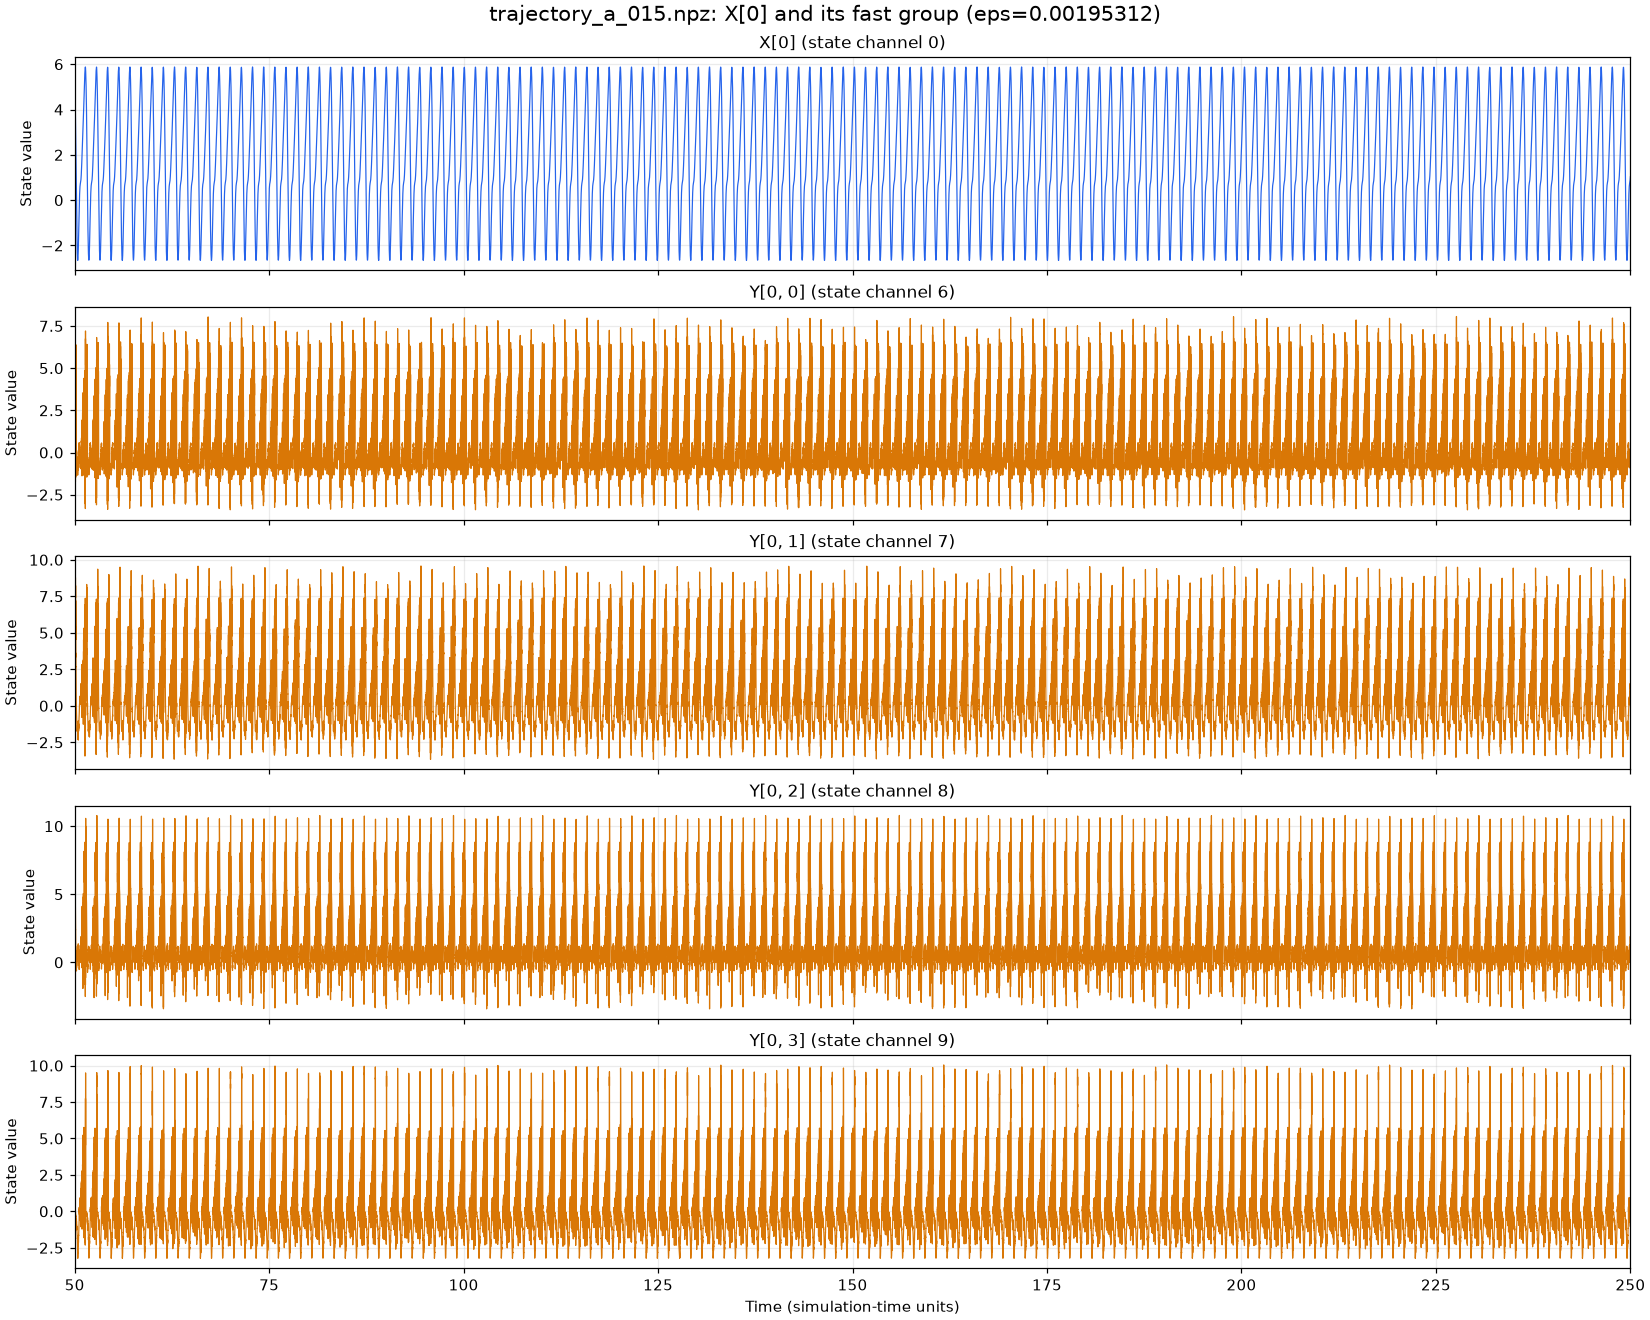

In [12]:
# Full-record overview: all saved samples from time 50 to 250.
plot_time_signals()

### Inspect the saved fast samples

Adjust `zoom_start` and `zoom_duration` below to inspect other intervals.
Markers identify actual saved observations; the default 0.05-unit interval spans
50 sampling intervals. A nearly flat slow signal over this short view is expected.

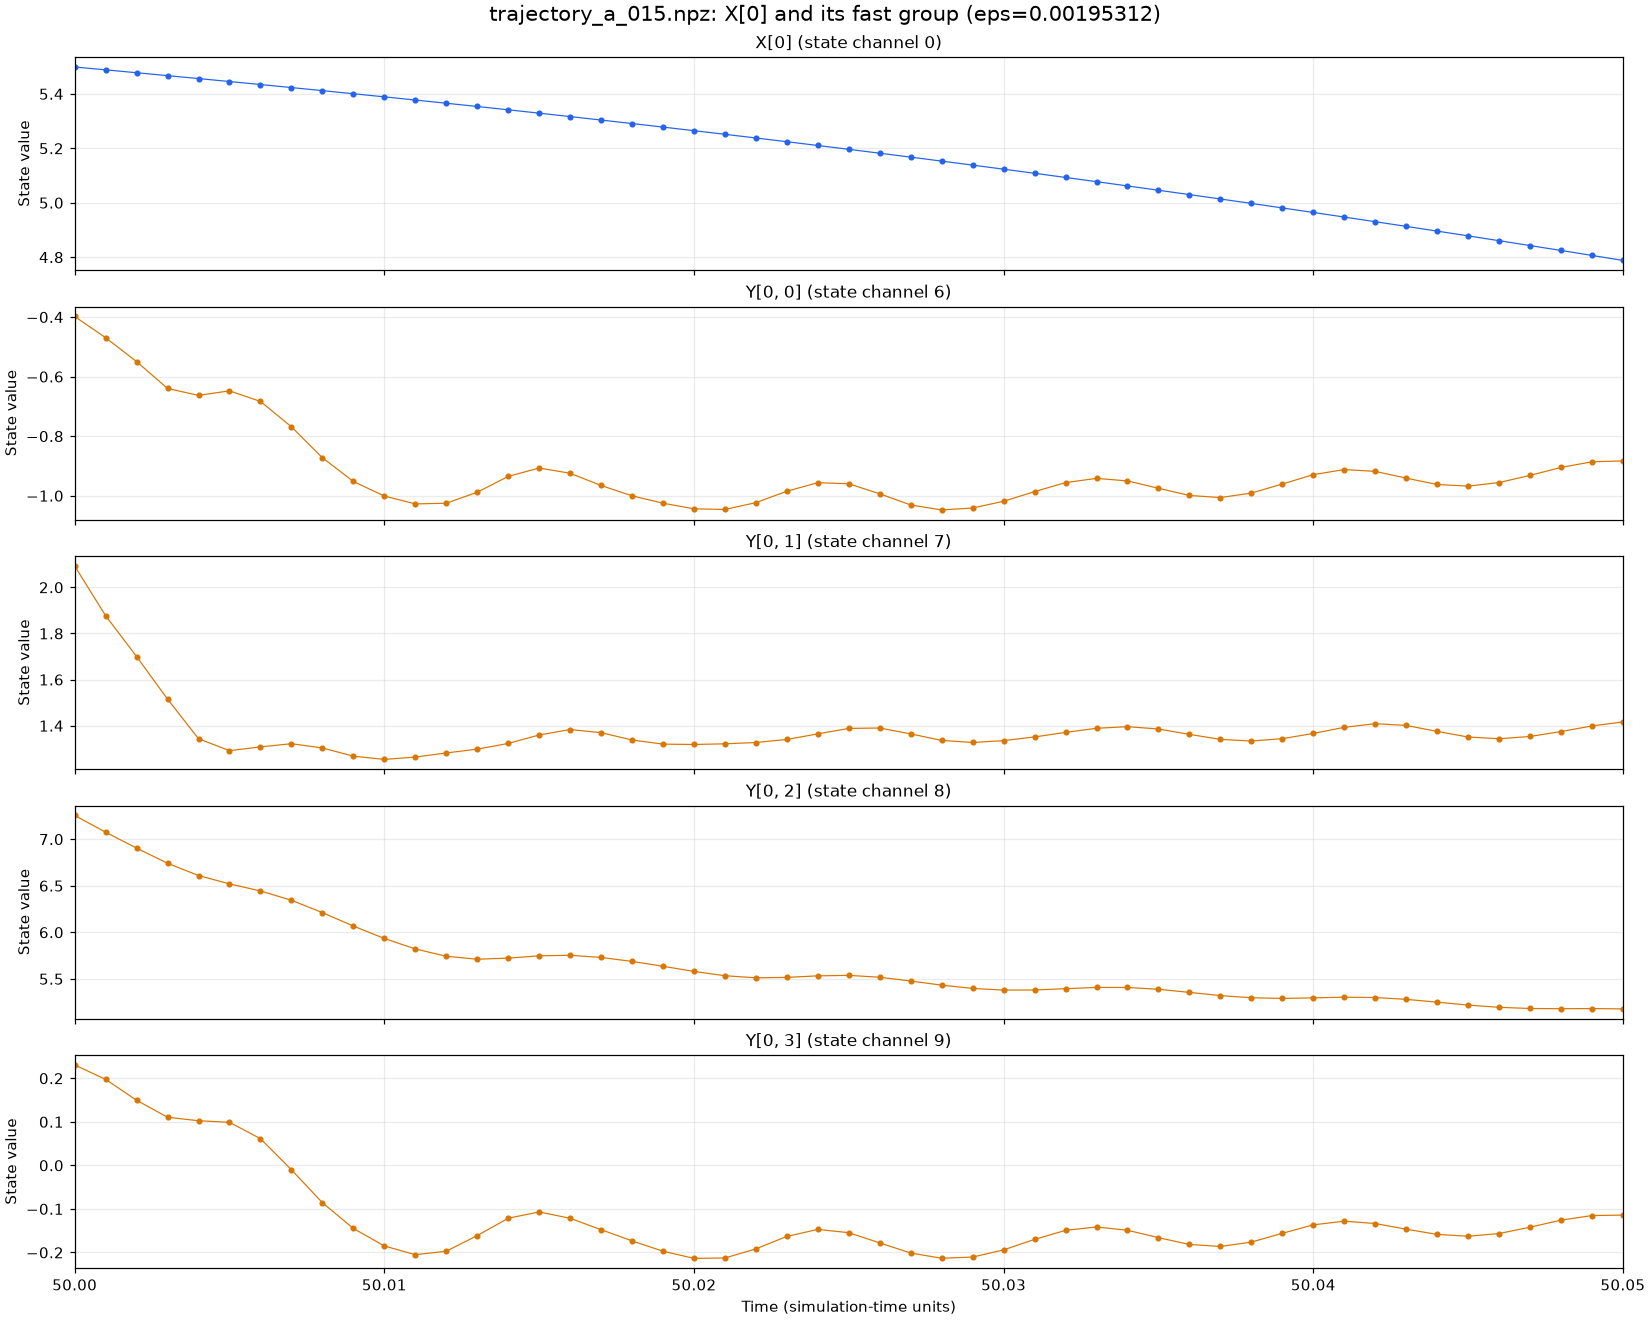

In [13]:
zoom_start = float(time_trajectory.time[0])
zoom_duration = 0.05
plot_time_signals(zoom_start, zoom_duration, show_samples=True)

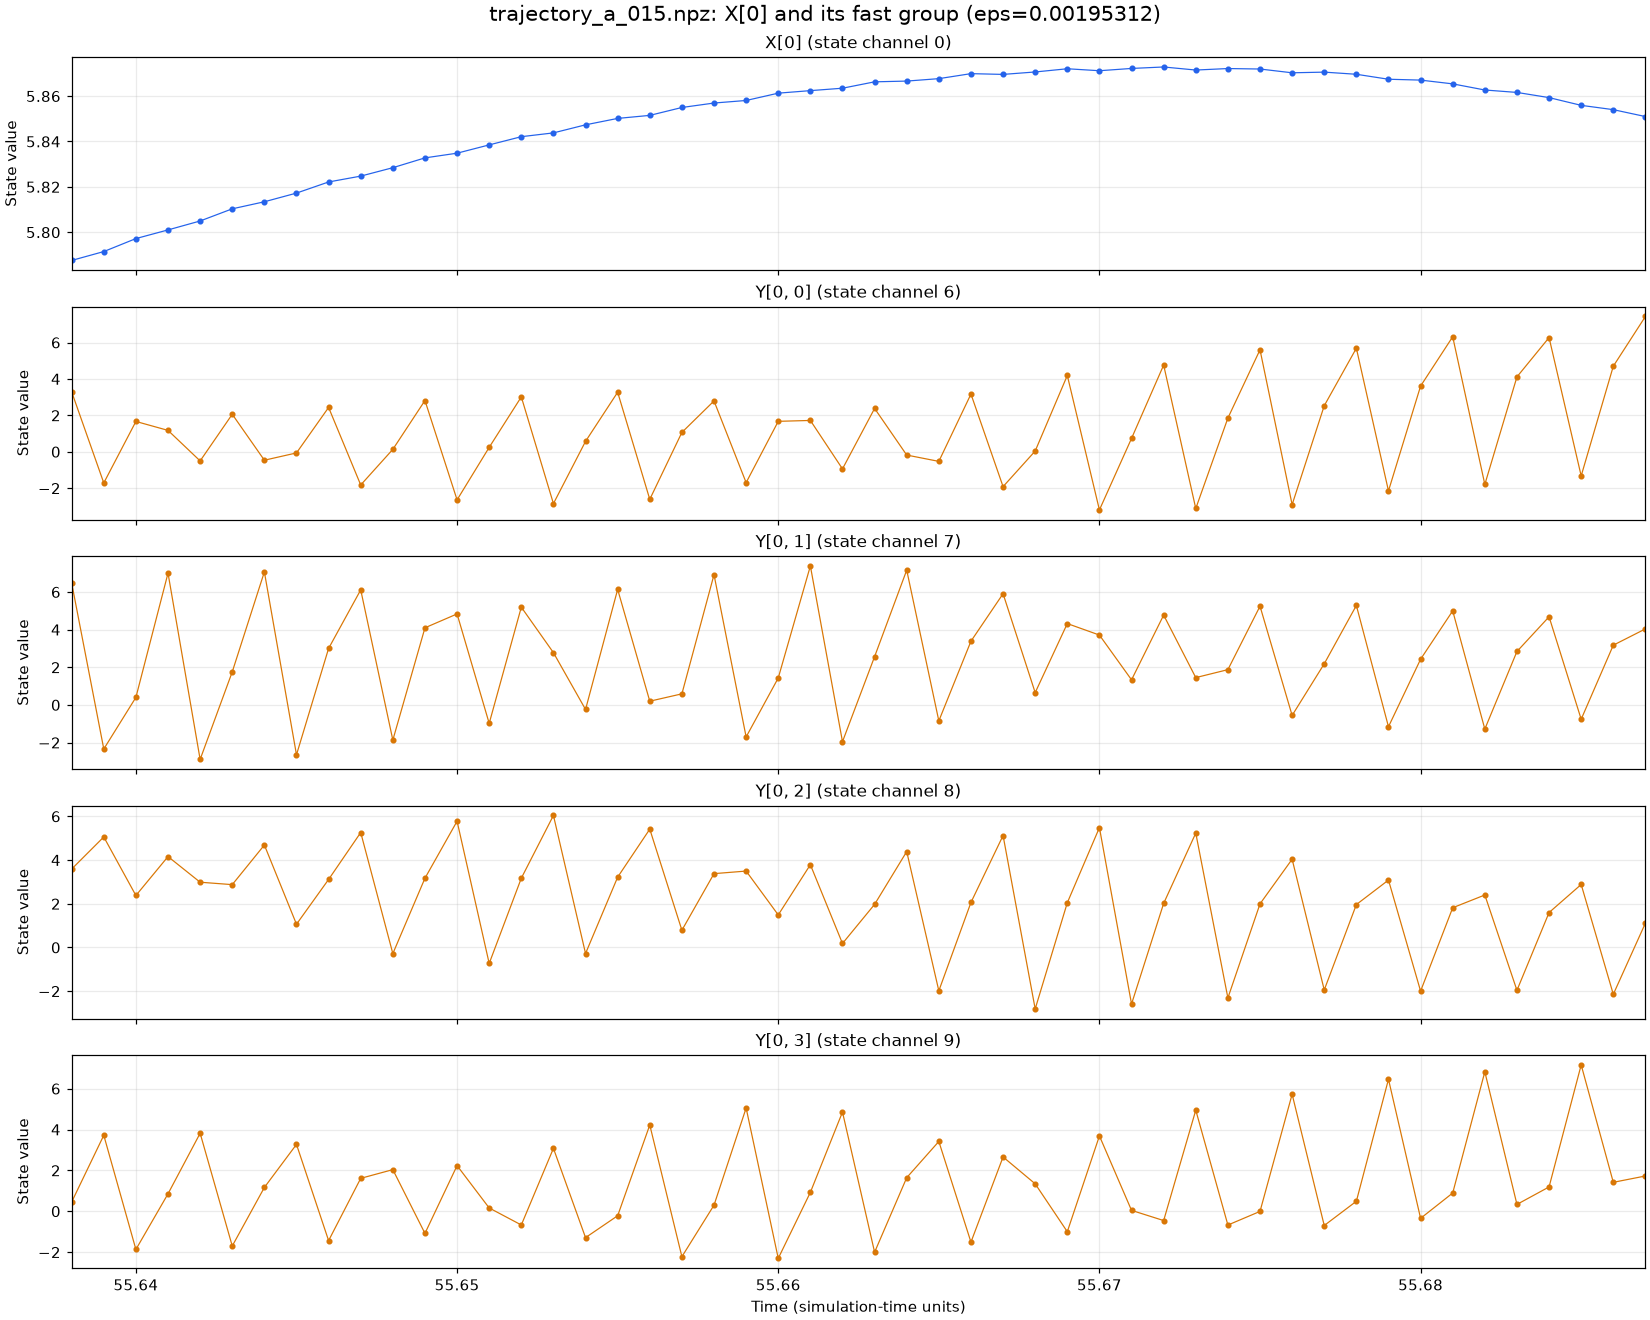

In [14]:
# Active region of trajectory_a_015: one slow variable and its four fast variables.
# Markers show the actual saved samples (spacing 0.001).
active_start = 55.638
active_duration = 0.05
plot_time_signals(active_start, active_duration, show_samples=True)
